### Step 1: Data Collection (Load and Inspect the Dataset)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df = pd.read_csv("Electric Vehicle Sales by State in India.csv")

print(df.info()) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96845 entries, 0 to 96844
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Year               96845 non-null  int64 
 1   Month_Name         96845 non-null  object
 2   Date               96845 non-null  object
 3   State              96845 non-null  object
 4   Vehicle_Class      96845 non-null  object
 5   Vehicle_Category   96845 non-null  object
 6   Vehicle_Type       96845 non-null  object
 7   EV_Sales_Quantity  96845 non-null  int64 
dtypes: int64(2), object(6)
memory usage: 5.9+ MB
None


In [4]:
df.head()

,Year,Month_Name,Date,State,Vehicle_Class,Vehicle_Category,Vehicle_Type,EV_Sales_Quantity
0,2014,jan,01-01-2014,Andhra Pradesh,ADAPTED VEHICLE,Others,Others,0
1,2014,jan,01-01-2014,Andhra Pradesh,AGRICULTURAL TRACTOR,Others,Others,0
2,2014,jan,01-01-2014,Andhra Pradesh,AMBULANCE,Others,Others,0
3,2014,jan,01-01-2014,Andhra Pradesh,ARTICULATED VEHICLE,Others,Others,0
4,2014,jan,01-01-2014,Andhra Pradesh,BUS,Bus,Bus,0


### Step 2: Data Preprocessing

In [105]:
# Handle missing values (if any)
def preprocessing(df):
    df.dropna(inplace=True)
    
    # Convert 'Date' column to datetime format
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
    
    # Check for duplicate rows
    df.drop_duplicates(inplace=True)
    
    # Standardize categorical column values (removing extra spaces, converting to lowercase)
    df['State'] = df['State'].str.strip().str.title()
    df['Vehicle_Class'] = df['Vehicle_Class'].str.strip().str.lower()
    df['Vehicle_Category'] = df['Vehicle_Category'].str.strip().str.lower()
    df['Vehicle_Type'] = df['Vehicle_Type'].str.strip().str.lower()
    return df

In [110]:
df = preprocessing(df)

In [107]:
def uniqueCat(df, columns):
    for col_name in columns:
        print(f"Unique Categories in {col_name} :-")
        print(df[col_name].unique())
        print('\n')

In [109]:
columns = ['Year', 'Month_Name', 'State', 'Vehicle_Class',
       'Vehicle_Category', 'Vehicle_Type']

uniqueCat(df, columns)

### Exploratory Data Analysis (EDA)

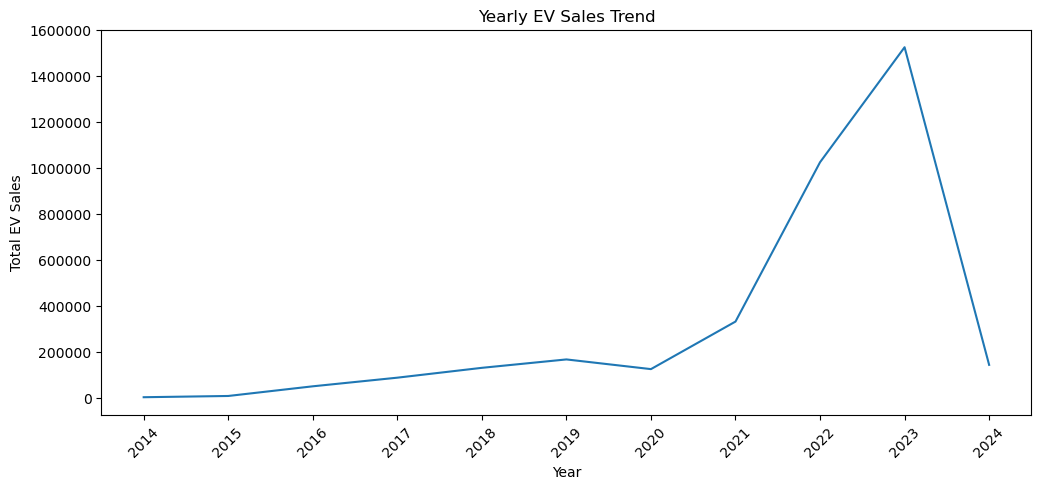

In [111]:
import matplotlib.ticker as mticker

# Sales trend over time
plt.figure(figsize=(12, 5))
sns.lineplot(x=df['Year'], y=df['EV_Sales_Quantity'], estimator='sum', errorbar=None)

plt.title('Yearly EV Sales Trend')
plt.xlabel('Year')
plt.ylabel('Total EV Sales')

plt.xticks(ticks=df['Year'].unique(), rotation=45)

plt.ticklabel_format(style='plain', axis='y')

plt.show()

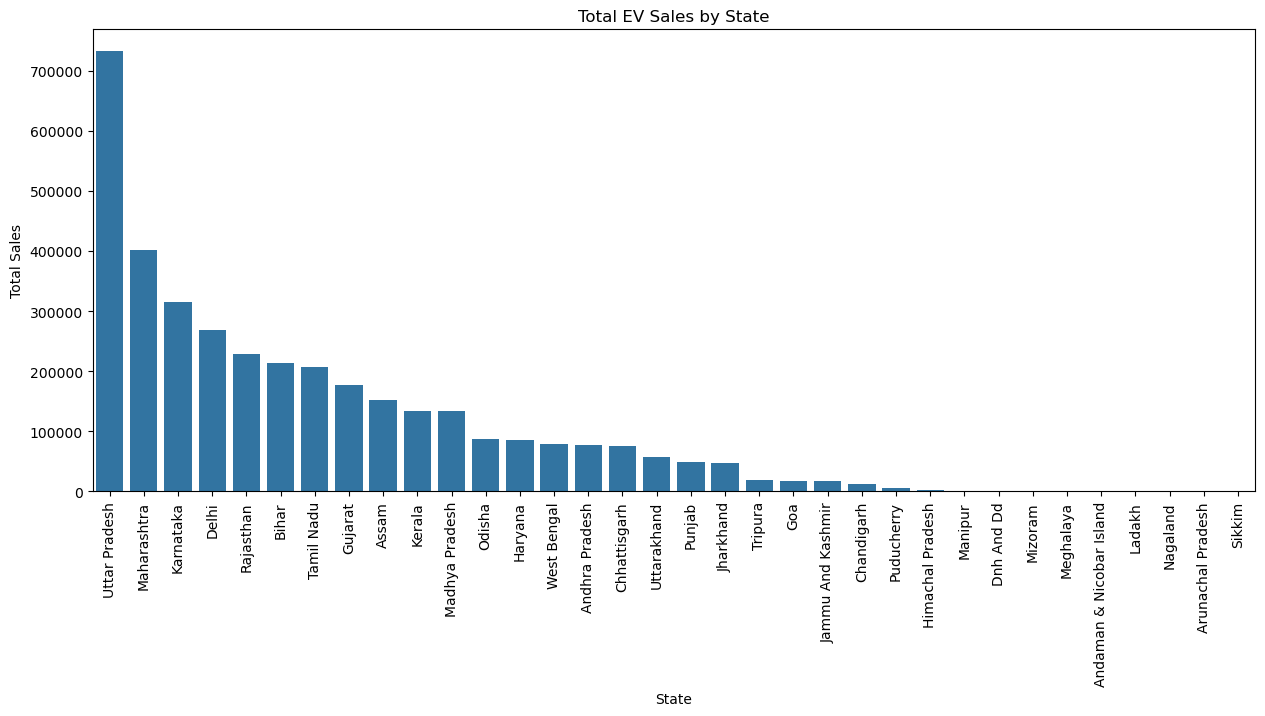

In [112]:
# Sales distribution by state
plt.figure(figsize=(15, 6))
sns.barplot(x=df.groupby('State')['EV_Sales_Quantity'].sum().sort_values(ascending=False).index,
            y=df.groupby('State')['EV_Sales_Quantity'].sum().sort_values(ascending=False).values)
plt.xticks(rotation=90)
plt.title('Total EV Sales by State')
plt.xlabel('State')
plt.ylabel('Total Sales')
plt.show()

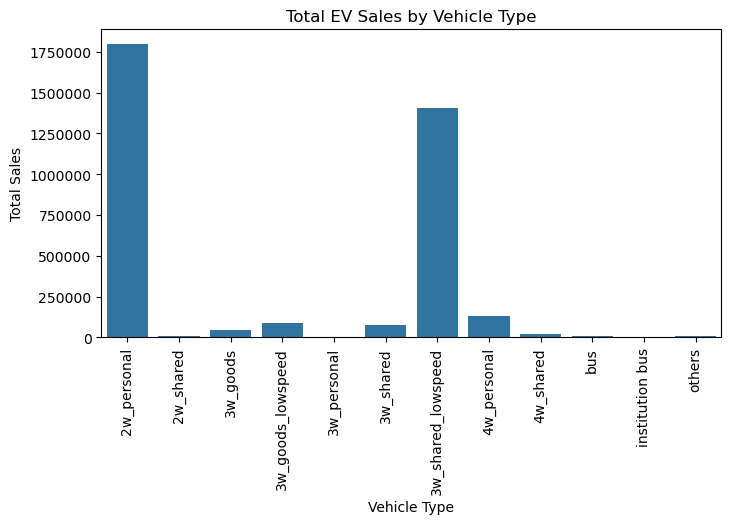

In [113]:
# Sales by vehicle type
plt.figure(figsize=(8, 4))
sns.barplot(x=df.groupby('Vehicle_Type')['EV_Sales_Quantity'].sum().index,
            y=df.groupby('Vehicle_Type')['EV_Sales_Quantity'].sum().values)
plt.title('Total EV Sales by Vehicle Type')
plt.xlabel('Vehicle Type')
plt.xticks(rotation=90)
plt.ticklabel_format(style='plain', axis='y')
plt.ylabel('Total Sales')
plt.show()

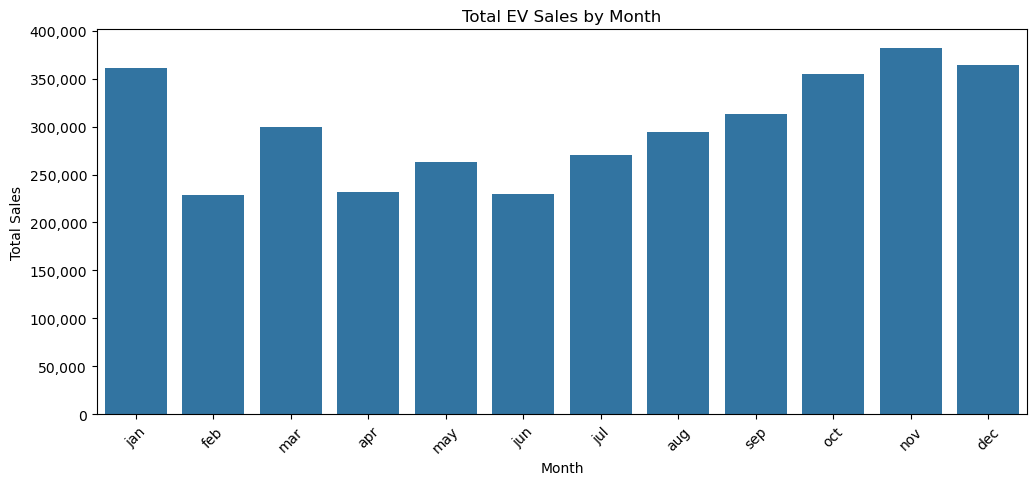

In [114]:
plt.figure(figsize=(12, 5))
monthly_sales = df.groupby('Month_Name')['EV_Sales_Quantity'].sum()

# Sorting months in calendar order
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
monthly_sales = monthly_sales.reindex(month_order)

sns.barplot(x=monthly_sales.index, y=monthly_sales.values)

plt.title('Total EV Sales by Month')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

# Format y-axis to avoid scientific notation
plt.gca().yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))

plt.show()

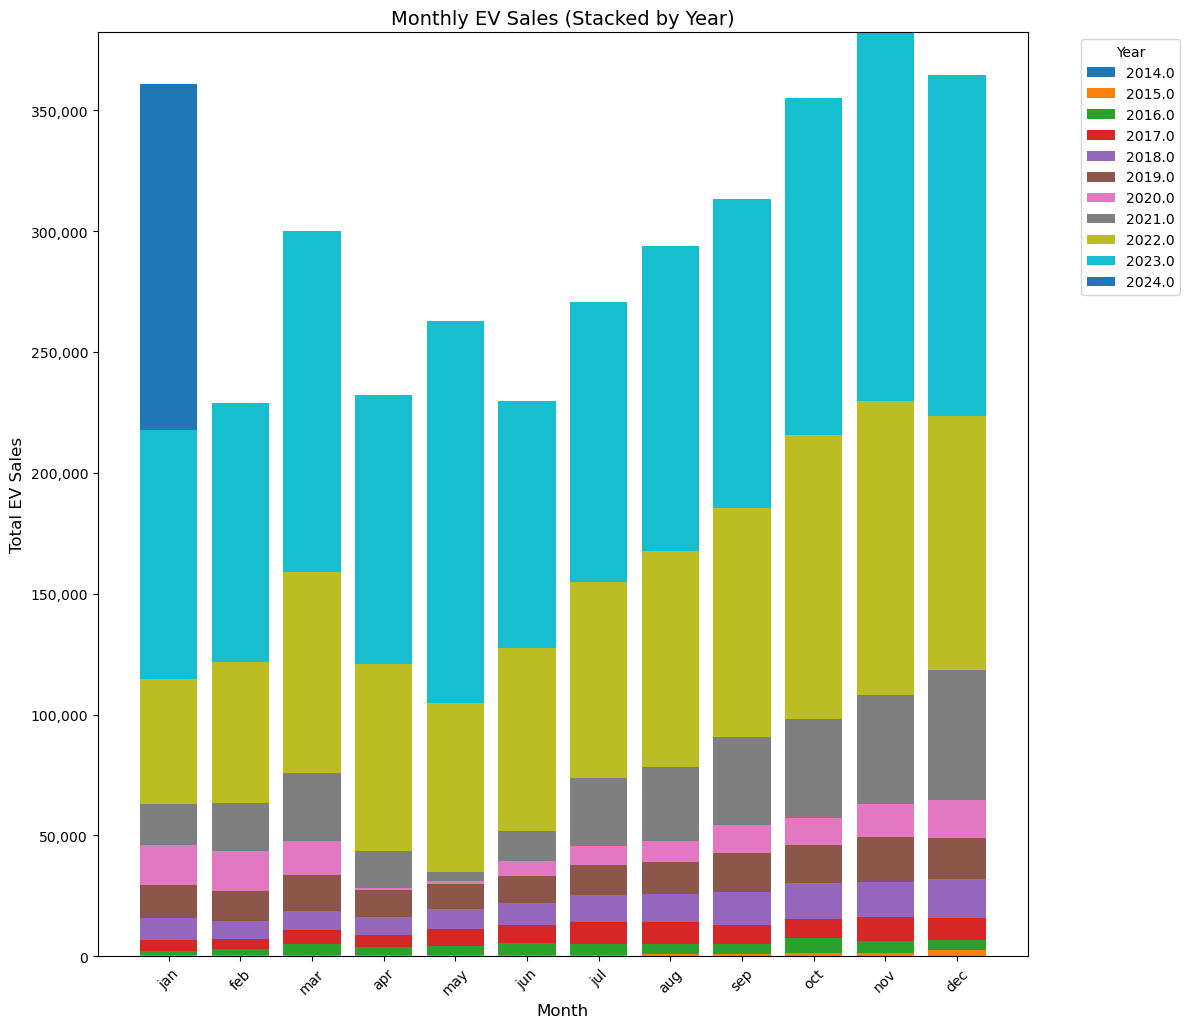

In [115]:
# Aggregating sales data by Month and Year
monthly_sales = df.groupby(['Month_Name', 'Year'])['EV_Sales_Quantity'].sum().reset_index()

# Pivot the data for stacked bar format
monthly_pivot = monthly_sales.pivot(index='Month_Name', columns='Year', values='EV_Sales_Quantity').fillna(0)

# Ensure correct month ordering (Jan-Dec)
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
monthly_pivot = monthly_pivot.reindex(month_order)

# Plot stacked bar chart
fig, ax = plt.subplots(figsize=(12, 12))

# Stacked bar plot
bottom_values = np.zeros(len(monthly_pivot))  # Initialize bottom for stacking
colors = sns.color_palette("tab10", len(monthly_pivot.columns))  # Unique colors for years

for idx, year in enumerate(monthly_pivot.columns):
    plt.bar(monthly_pivot.index, monthly_pivot[year], bottom=bottom_values, label=year, color=colors[idx])
    bottom_values += monthly_pivot[year]  # Update bottom for stacking

# Labels and formatting
plt.title('Monthly EV Sales (Stacked by Year)', fontsize=14)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total EV Sales', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')

# Format y-axis to avoid scientific notation
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))

plt.show()

In [116]:
monthly_pivot

Year,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0
Month_Name,,,,,,,,,,,
jan,232.0,174.0,1946.0,4582.0,9003.0,13379.0,16865.0,17025.0,51476.0,102839.0,143182.0
feb,171.0,182.0,2499.0,4411.0,7372.0,12228.0,16569.0,20073.0,58056.0,107178.0,0.0
mar,220.0,222.0,4520.0,5992.0,7696.0,15154.0,14066.0,28115.0,83080.0,140823.0,0.0
apr,252.0,175.0,3443.0,5054.0,7335.0,11185.0,975.0,15020.0,77522.0,111233.0,0.0
may,186.0,195.0,4004.0,7059.0,8261.0,10082.0,1311.0,3602.0,69916.0,158131.0,0.0
jun,149.0,287.0,5119.0,7509.0,8833.0,11159.0,6486.0,12317.0,75852.0,102043.0,0.0
jul,199.0,383.0,4380.0,9047.0,11397.0,12479.0,7799.0,28146.0,80887.0,115756.0,0.0
aug,180.0,711.0,4022.0,9169.0,11792.0,13252.0,8558.0,30818.0,89012.0,126508.0,0.0
sep,168.0,968.0,4174.0,7735.0,13588.0,16145.0,11355.0,36604.0,94903.0,127793.0,0.0


In [58]:
class_sales = df.groupby(['Vehicle_Class'])['EV_Sales_Quantity'].sum().reset_index()
class_sales[class_sales.EV_Sales_Quantity>0].sort_values("EV_Sales_Quantity", ascending=False)

### Feature Engineering

In [119]:
import pandas as pd
import numpy as np

def feature_engineering(df_fe):
    # Extract new date-based features
    df_fe['Month_Num'] = df_fe['Date'].dt.month  # Extract month as number (1-12)
    df_fe['Quarter'] = df_fe['Date'].dt.quarter  # Extract quarter (1-4)
    df_fe['Day_of_Week'] = df_fe['Date'].dt.dayofweek  # Monday=0, Sunday=6
    df_fe['Is_Weekend'] = df_fe['Day_of_Week'].isin([5, 6]).astype(int)  # 1 if Sat/Sun, else 0
    
    # Define key festive months in India (Diwali, Dussehra, Navratri, Christmas)
    festive_months = [10, 11, 12]
    df_fe['Is_Festive_Season'] = df_fe['Month_Num'].isin(festive_months).astype(int)
    
    # Sales trend features
    df_fe = df_fe.sort_values(['State', 'Date'])  # Ensure sorted order for rolling calculations
    df_fe['Rolling_Mean_Sales_3M'] = df_fe.groupby('State')['EV_Sales_Quantity'].transform(lambda x: x.rolling(window=3, min_periods=1).mean())
    
    # Yearly Growth Rate: (Current Year Sales - Last Year Sales) / Last Year Sales
    df_fe['Previous_Year_Sales'] = df_fe.groupby(['State', 'Month_Num'])['EV_Sales_Quantity'].shift(12)
    df_fe['Yearly_Growth_Rate'] = ((df_fe['EV_Sales_Quantity'] - df_fe['Previous_Year_Sales']) / df_fe['Previous_Year_Sales']).fillna(0)
    
    # One-Hot Encoding for categorical features
    categorical_cols = ['State', 'Vehicle_Class', 'Vehicle_Category', 'Vehicle_Type']
    df_fe = pd.get_dummies(df_fe, columns=categorical_cols, drop_first=True)
    
    # Drop intermediate column
    df_fe.drop(columns=['Previous_Year_Sales', 'Month_Name', 'Date'], inplace=True)
    return df_fe

In [120]:
df_fe = feature_engineering(df.copy())

# Replace inf values with NaN
df_fe.replace([np.inf, -np.inf], np.nan, inplace=True)

# Fill NaN values with median (better than mean for skewed data)
df_fe = df_fe.dropna()

In [121]:
print("NaN values count:\n", df_fe.isna().sum().sum())
print("Infinity values count:", np.isinf(df_fe).sum().sum())
print("Max value in dataset:", df_fe.max().max())
print("Min value in dataset:", df_fe.min().min())

NaN values count:
 0
Infinity values count: 0
Max value in dataset: 15320.0
Min value in dataset: -1.0


### Feature Scaling and Modeling

In [100]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Define features and target variable
target = 'EV_Sales_Quantity'
features = [col for col in df_fe.columns if col != target]

X = df_fe[features]
y = df_fe[target]

# Split data into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)
}

# Train models and evaluate performance
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    print(f"Model: {name}")
    print(f"R² Score: {r2:.4f}")
    # print(f"MAE: {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print("-" * 40)

Model: Linear Regression
R² Score: 0.3880
MAE: 12.08
RMSE: 97.57
----------------------------------------
Model: Random Forest
R² Score: 0.9551
MAE: 1.12
RMSE: 26.42
----------------------------------------
Model: XGBoost
R² Score: 0.9854
MAE: 1.20
RMSE: 15.09
----------------------------------------


In [102]:
model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Model: {name}")
print(f"R² Score: {r2:.4f}")
# print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")

Model: XGBoost
R² Score: 0.9854
RMSE: 15.09
